In [7]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

path = "SierraNevada_DEM/USGS_OPR_CA_SierraNevada_B22_be_11SKA7089.tif"
# path = "output/TerrainSR_Result.tif"

with rasterio.open(path) as src:
    data = src.read(1, masked=True)

    valid = ~np.ma.getmaskarray(data)
    valid &= np.isfinite(data.data)

    print("Size:", src.width, src.height)
    print("Data type:", src.dtypes[0])
    print("NoData value:", src.nodata)
    print("Valid pixels:", valid.sum())
    print("Total pixels:", valid.size)
    print("Valid percentage:", valid.mean() * 100)

    if valid.any():
        print("Minimum elevation:", data.data[valid].min())
        print("Maximum elevation:", data.data[valid].max())

Size: 2000 2000
Data type: float32
NoData value: -999999.0
Valid pixels: 4000000
Total pixels: 4000000
Valid percentage: 100.0
Minimum elevation: 190.42892
Maximum elevation: 230.4254


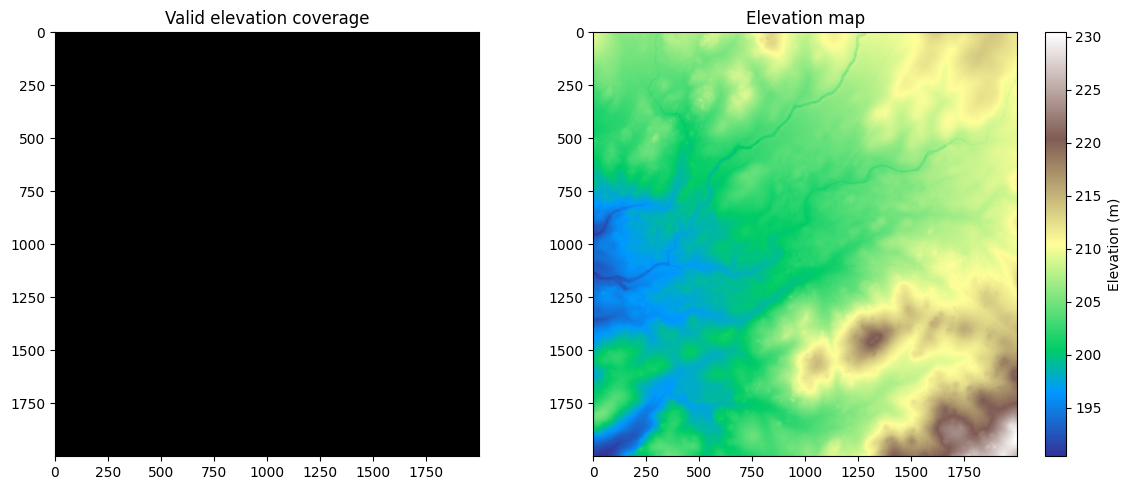

In [8]:
with rasterio.open(path) as src:
    dem = src.read(1, masked=True)

valid = (
    ~np.ma.getmaskarray(dem)
    & np.isfinite(dem.data)
)

elevation = np.ma.array(
    dem.data,
    mask=~valid
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Valid elevation coverage
axes[0].imshow(valid, cmap="gray")
axes[0].set_title("Valid elevation coverage")

# Actual elevation values
image = axes[1].imshow(
    elevation,
    cmap="terrain"
)
axes[1].set_title("Elevation map")
fig.colorbar(image, ax=axes[1], label="Elevation (m)")

plt.tight_layout()
plt.show()


In [1]:
import rasterio
import numpy as np

with rasterio.open("output/Terrain_Input_128.tif") as src:
    elevation = src.read(1)

    print("Data type:", elevation.dtype)
    print("NoData:", src.nodata)

    valid = elevation[np.isfinite(elevation)]

    if src.nodata is not None:
        valid = valid[valid != src.nodata]

    print("Minimum:", valid.min())
    print("Maximum:", valid.max())
    print("Mean:", valid.mean())
    print("Std:", valid.std())

    print("First row:")
    print(elevation[0, :20])

Data type: float32
NoData: None
Minimum: 199.23851
Maximum: 203.07903
Mean: 201.50789
Std: 0.79320127
First row:
[201.19327 201.22823 201.21574 201.23134 201.27095 201.32657 201.396
 201.47316 201.50807 201.47467 201.42726 201.42908 201.40541 201.40388
 201.37938 201.39088 201.41234 201.387   201.33905 201.30782]
